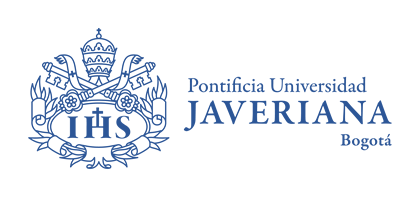
# Aprendizeje Profundo
## Taller 2 — Aprendizaje profundo por refuerzo


**Objetivo:**

Implementar, entrenar y evaluar un agente de aprendizaje profundo por refuerzo mediante Double Deep Q-Network (Double DQN) en un entorno Atari, analizando las decisiones de diseño de la arquitectura neuronal, la estrategia de exploración y el proceso de aprendizaje de la función de valor Q.

**Requisitos:** Python 3.10+, Jupyter o Colab, preferiblemente GPU. El entrenamiento completo de Atari puede requerir millones de interacciones, tome conclusiones y métricas con lo que alcance a probar.

Siga las instrucciones de entrega de talleres contempladas en la presentación de inicio del curso

### ¿Qué son ALE y Gymnasium?

Para el desarrollo de este taller de Aprendizaje por Refuerzo, dependemos de dos librerías fundamentales que estructuran la interacción del agente con el entorno de Atari:

1. **ALE (Arcade Learning Environment):**
   - Es una plataforma de software diseñada para evaluar y desarrollar agentes de inteligencia artificial de propósito general.
   - Actúa como un emulador interno del sistema **Atari 2600**, permitiendo que programas externos interactúen con decenas de videojuegos clásicos (como *Pong*, *Breakout*, *Space Invaders*, entre otros).
   - Proporciona acceso directo a la señal de video (los píxeles en pantalla), la puntuación (recompensa) y la memoria del sistema (RAM), emulando los controles de la consola original.

2. **Gymnasium:**
   - Es un fork mantenido activamente de la clásica librería `Gym` de OpenAI.
   - Ofrece una **interfaz estándar unificada** para problemas de aprendizaje por refuerzo en Python.
   - Define la estructura básica del ciclo de interacción del agente a través de una API común:
     - El método `reset()` para inicializar el entorno.
     - El método `step(action)` para ejecutar una acción y recibir la nueva observación, recompensa e indicadores de término (`terminated` y `truncated`).
   - En este notebook, Gymnasium actúa como la capa superior que envuelve a **ALE** (`ALE/Pong-v5`), permitiendo aplicar wrappers estandarizados (como `AtariPreprocessing` y `FrameStackObservation`) de manera limpia y modular.

In [ ]:
# Descomentar para instalar en Jupyter / Colab:
!pip install -q "gymnasium>=1.1,<2" "ale-py>=0.11,<1" "torch>=2.2" matplotlib numpy imageio

In [ ]:
import random
from collections import deque
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import ale_py
import imageio
from IPython.display import Image, display



In [ ]:
gym.register_envs(ale_py)
SEED = 42
random.seed(SEED); np.random.seed(SEED);

### Descripción General de la API de Gymnasium

El núcleo de Gymnasium se basa en un ciclo de interacción continuo entre el **Agente** y el **Entorno** (*Environment*). El flujo estándar de trabajo utiliza los siguientes componentes clave:

* **`gym.make(env_id, ...)`**: Instancia el entorno a partir de su identificador (en nuestro caso, `"ALE/Pong-v5"`). Aquí se puede configurar el modo de renderizado (por ejemplo, `render_mode="rgb_array"`).
* **`env.reset(seed=...)`**: Inicializa el entorno a un estado inicial. Es crucial para la reproducibilidad pasar una semilla (`seed`). Retorna una tupla con:
  - `observation`: El estado inicial del entorno.
  - `info`: Un diccionario con metadatos útiles específicos del juego (p. ej., número de vidas).
* **`env.step(action)`**: Ejecuta una acción elegida por el agente y devuelve cinco valores esenciales:
  1. `observation`: El nuevo estado (píxeles, vectores, etc.) tras aplicar la acción.
  2. `reward`: Una señal escalar (número flotante) que indica el beneficio inmediato de la acción.
  3. `terminated`: Un booleano que indica si el agente alcanzó un estado terminal natural de fin de juego (ganar, perder o morir).
  4. `truncated`: Un booleano que indica si el episodio terminó de manera forzada debido a un límite de tiempo o condición externa.
  5. `info`: Información de diagnóstico auxiliar.
* **`env.close()`**: Libera de forma segura los recursos del sistema y las ventanas gráficas del emulador al finalizar la interacción.

## 1. Crear y explorar un entorno Atari

En la siguiente celda se instancia un gimnasio de ALE usando el API de OpenGymnasium. Podemos obtener el espacio de observaciones (obs. del entorno), el espacio de acciones del entorno y las acciones que pueden ser realizadas en el

In [ ]:
# Instanciamos modelo PONG
probe = gym.make("ALE/Pong-v5", render_mode="rgb_array")
# Se inicia el gimnasio en un estado inicial
obs, info = probe.reset(seed=SEED)

print("Espacio de observaciones:", probe.observation_space)
print("Espacio de acciones:", probe.action_space)
print("Forma / tipo:", obs.shape, obs.dtype)
print("Espacio de acciones", probe.action_space)
print("Acciones:", probe.unwrapped.get_action_meanings())
plt.figure(figsize=(5,6))
plt.imshow(obs); plt.axis("off"); plt.title("Observación inicial (RGB)"); plt.show()
probe.close()

Escojamos de forma aleatoria una serie de acciones mediante `probe.action_space.sample()`





In [ ]:
probe = gym.make("ALE/Pong-v5", render_mode="rgb_array")
obs, info = probe.reset(seed=SEED)
rewards = []
obs_history=[]
obs_history.append(obs)
for t in range(300):
    action = probe.action_space.sample()
    obs, reward, terminated, truncated, info = probe.step(action)
    obs_history.append(obs)
    rewards.append(reward)
    if terminated or truncated:
        # Reinicia el juego
        obs, info = probe.reset()

print("Recompensas distintas (muestra):", sorted(set(rewards)))
plt.figure(figsize=(5,6)); plt.imshow(obs); plt.axis("off")
plt.title("Observación después de interacciones aleatorias"); plt.show()
probe.close()

In [ ]:


# Guardar el historial de observaciones como un archivo GIF animado
gif_path = "random_agent_pong.gif"
# Guardamos cada frame reduciendo el muestreo para mantener un archivo ligero (un frame cada 2 pasos)
imageio.mimsave(gif_path, obs_history[::2], fps=30)

# Mostrar el GIF directamente en el notebook
display(Image(filename=gif_path))

In [ ]:
# Graficar las recompensas obtenidas durante la interacción aleatoria
cumulative_rewards = np.cumsum(rewards)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico 1: Recompensas individuales
axes[0].plot(rewards, color='royalblue', alpha=0.6, label='Recompensa por paso')
axes[0].set_title('Recompensas por Paso (Agente Aleatorio)')
axes[0].set_xlabel('Paso de tiempo (t)')
axes[0].set_ylabel('Recompensa')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Gráfico 2: Recompensa acumulada
axes[1].plot(cumulative_rewards, color='crimson', linewidth=2, label='Recompensa acumulada')
axes[1].set_title('Progreso de la Recompensa Acumulada')
axes[1].set_xlabel('Paso de tiempo (t)')
axes[1].set_ylabel('Suma acumulada')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.suptitle('Análisis de Recompensas de la Exploración Aleatoria', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 2. Simulación con agente Heurístico

Para explorar mejor el juego, podemos implementar una política simple que emule el comportamiento humano básico: seguir la posición vertical de la pelota. Aunque no es perfecta por el retraso de la emulación, nos da una visión mucho más realista de la dinámica de Pong.

In [ ]:
# Reiniciamos el entorno para obtener imágenes limpias
probe = gym.make("ALE/Pong-v5", render_mode="rgb_array")
obs, info = probe.reset(seed=SEED)

# Heurística simple: Seguir la pelota en el eje Y
# En Pong de Atari, la raqueta derecha (nuestra) es de color verde y se mueve con:
# 2 (RIGHT / UP) y 3 (LEFT / DOWN)

def heuristic_agent(obs):
    # El área de juego útil excluye los bordes y el marcador (Y entre 34 y 194)
    play_area = obs[34:194, :, :]

    # Buscar los píxeles claros de la pelota (generalmente de color blanco/grisáceo)
    ball_pixels = np.argwhere((play_area[:, :, 0] > 140) & (play_area[:, :, 1] > 140))
    if len(ball_pixels) > 0:
        ball_y = ball_pixels[:, 0].mean() + 34
    else:
        ball_y = 110 # Posición central si no se detecta la pelota

    # Encontrar nuestra raqueta (barra verde en el extremo derecho, x aprox 140-144)
    # El verde característico de la raqueta tiene una alta intensidad en el canal G (verde) y baja en R y B
    paddle_pixels = np.argwhere((obs[34:194, 140:144, 1] > 100) & (obs[34:194, 140:144, 0] < 100))
    if len(paddle_pixels) > 0:
        paddle_y = paddle_pixels[:, 0].mean() + 34
    else:
        paddle_y = 110 # En caso de que se oculte o no se detecte, mantener el centro

    # Decidir acción basada en la diferencia de posiciones
    if ball_y < paddle_y - 2:
        return 2  # Subir (UP)
    elif ball_y > paddle_y + 2:
        return 3  # Bajar (DOWN)
    return 0  # Quieto (NOOP)

# Ejecutar demostración con el agente corregido
frames = []
rewards = []
for t in range(500):
    action = heuristic_agent(obs)
    obs, reward, terminated, truncated, info = probe.step(action)
    rewards.append(reward)
    # Guardar todos los frames para la generación del GIF
    frames.append(obs)
    if terminated or truncated:
        break

probe.close()
print("Recompensas obtenidas en este fragmento:", set(rewards))

In [ ]:


heuristic_gif_path = "heuristic_agent_pong.gif"
imageio.mimsave(heuristic_gif_path, frames, fps=30)

# Mostrar el GIF generado
display(Image(filename=heuristic_gif_path))

In [ ]:
# Graficar las recompensas de la simulación heurística
heuristic_cumulative = np.cumsum(rewards)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico 1: Recompensas por paso
axes[0].plot(rewards, color='teal', alpha=0.6, label='Recompensa heurística')
axes[0].set_title('Recompensas por Paso (Agente Heurístico)')
axes[0].set_xlabel('Paso de tiempo (t)')
axes[0].set_ylabel('Recompensa')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Gráfico 2: Recompensa acumulada
axes[1].plot(heuristic_cumulative, color='darkorange', linewidth=2, label='Recompensa acumulada')
axes[1].set_title('Progreso de la Recompensa (Agente Heurístico)')
axes[1].set_xlabel('Paso de tiempo (t)')
axes[1].set_ylabel('Suma acumulada')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.suptitle('Análisis de Recompensas de la Exploración con Heurística de Seguimiento', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 3. Preprocesamiento y apilamiento temporal
PAra acelerar el procesamiento del entorno se crea una función de procesamiento del entorno $\phi$. Se utiliza una imagen en escala de grises de **84 × 84** píxeles, cuatro fotogramas consecutivos y un *frame skip* de 4 dentro de `AtariPreprocessing`.

**Importante:** configurar `frameskip=1` en el entorno base; de lo contrario se aplicaría *frame skip* tanto en el entorno como en el wrapper. Mantener las observaciones como `uint8` en memoria y normalizarlas a `[0,1]` al entrar a la red para simplificar estado



In [ ]:
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation

def make_env(seed=None):
    env = gym.make("ALE/Pong-v5", frameskip=1, repeat_action_probability=0.25)
    env = AtariPreprocessing(env, noop_max=30, frame_skip=4,
                             screen_size=84, grayscale_obs=True,
                             grayscale_newaxis=False, scale_obs=False)
    env = FrameStackObservation(env, stack_size=4)
    if seed is not None:
        env.reset(seed=seed)
        env.action_space.seed(seed)
    return env

env = make_env(SEED)
state, info = env.reset(seed=SEED)
print("Estado preprocesado:", state.shape, state.dtype)
fig, axes = plt.subplots(1, 4, figsize=(12,3))
for i, ax in enumerate(axes):
    ax.imshow(state[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Frame {i+1}"); ax.axis("off")
plt.show()
env.close()

### 4. Implementación de Double DQN con Keras y TensorFlow

Definiremos primero la arquitectura de la Red Convolucional (Q-Network) en Keras compatible con la entrada preprocesada de dimensiones

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from collections import deque
import random

def create_q_model(n_actions):
    n_actions = int(n_actions)

    # Entrada de (4, 84, 84). Para procesarlo en Keras de manera estándar,
    # transponemos o definimos el formato de canales como 'channels_first' (NCHW)
    inputs = layers.Input(shape=(4, 84, 84))

    # Transponer a (84, 84, 4) para usar el formato estándar 'channels_last' de CPU/GPU en Keras
    x = layers.Permute((2, 3, 1))(inputs)

    # Normalización de [0, 255] a [0.0, 1.0]
    x = layers.Lambda(lambda t: t / 255.0)(x)

    # Capas Convolucionales
    x = layers.Conv2D(32, kernel_size=8, strides=4, activation="relu")(x)
    x = layers.Conv2D(64, kernel_size=4, strides=2, activation="relu")(x)
    x = layers.Conv2D(64, kernel_size=3, strides=1, activation="relu")(x)
    x = layers.Flatten()(x)

    # Capa Densa y salida
    x = layers.Dense(512, activation="relu")(x)
    # Se calcula valor Q para todas las acciones al tiempo
    outputs = layers.Dense(n_actions, activation="linear")(x)

    return models.Model(inputs=inputs, outputs=outputs)

# Probar la creación del modelo
test_model = create_q_model(n_actions=6)
test_model.summary()

Ahora creamos el **Replay Buffer** para almacenar las transiciones `(estado, acción, recompensa, siguiente_estado, terminado)` y la clase del agente **Double DQNAgent**.

In [ ]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):
        self.buffer.append((np.array(state, dtype=np.uint8), action, reward, np.array(next_state, dtype=np.uint8), done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (np.array(states, dtype=np.uint8),
                np.array(actions, dtype=np.int32),
                np.array(rewards, dtype=np.float32),
                np.array(next_states, dtype=np.uint8),
                np.array(dones, dtype=np.float32))

    def __len__(self):
        return len(self.buffer)

class DoubleDQNAgent:
    def __init__(self, n_actions, lr=1e-4, gamma=0.99, buffer_capacity=10000):
        self.n_actions = n_actions
        self.gamma = gamma

        # Red Online y Red Target
        self.model = create_q_model(n_actions)
        self.target_model = create_q_model(n_actions)
        self.update_target_network()

        self.optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
        self.loss_fn = tf.keras.losses.Huber() # Huber loss / Smooth L1 equivalente
        self.buffer = ReplayBuffer(buffer_capacity)

    def update_target_network(self):
        self.target_model.set_weights(self.model.get_weights())

    def choose_action(self, state, epsilon):
        if random.random() < epsilon:
            return random.randrange(self.n_actions)
        state_tensor = tf.convert_to_tensor(np.expand_dims(state, axis=0), dtype=tf.float32)
        q_values = self.model(state_tensor, training=False)
        return int(tf.argmax(q_values[0]).numpy())

    @tf.function
    def train_step_tf(self, states, actions, rewards, next_states, dones):
        # 1. Obtener las acciones seleccionadas por la red online para el siguiente estado
        next_online_q = self.model(next_states, training=False)
        next_actions = tf.argmax(next_online_q, axis=1, output_type=tf.int32)

        # 2. Evaluar esas acciones con la red target (Lógica Double DQN)
        next_target_q = self.target_model(next_states, training=False)
        indices = tf.stack([tf.range(tf.shape(next_actions)[0]), next_actions], axis=1)
        max_next_q = tf.gather_nd(next_target_q, indices)

        # 3. Calcular los objetivos TD (TD Targets)
        targets = rewards + self.gamma * (1.0 - dones) * max_next_q

        with tf.GradientTape() as tape:
            # Obtener el Q-value estimado por la red online para las acciones tomadas
            q_values = self.model(states, training=True)
            action_indices = tf.stack([tf.range(tf.shape(actions)[0]), actions], axis=1)
            predicted_q = tf.gather_nd(q_values, action_indices)

            # Calcular pérdida
            loss = self.loss_fn(targets, predicted_q)

        # Aplicar gradientes
        grads = tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.model.trainable_variables))
        return loss

    def train(self, batch_size):
        if len(self.buffer) < batch_size:
            return 0.0
        states, actions, rewards, next_states, dones = self.buffer.sample(batch_size)

        # Convertir a tensores
        states_t = tf.convert_to_tensor(states, dtype=tf.float32)
        actions_t = tf.convert_to_tensor(actions, dtype=tf.int32)
        rewards_t = tf.convert_to_tensor(rewards, dtype=tf.float32)
        next_states_t = tf.convert_to_tensor(next_states, dtype=tf.float32)
        dones_t = tf.convert_to_tensor(dones, dtype=tf.float32)

        loss = self.train_step_tf(states_t, actions_t, rewards_t, next_states_t, dones_t)
        return float(loss.numpy())

Definimos una pequeña rutina de demostración para verificar que el agente interactúa y entrena sin errores en el entorno Gymnasium preprocesado.

In [ ]:
# Inicializar el entorno preprocesado y el agente
test_env = make_env(SEED)
state, _ = test_env.reset(seed=SEED)
n_actions = test_env.action_space.n

agent = DoubleDQNAgent(n_actions=n_actions, buffer_capacity=1000)

# Simular unas cuantas transiciones y agregarlas al Buffer para probar un paso de entrenamiento
for _ in range(2000):
    action = agent.choose_action(state, epsilon=0.5)
    next_state, reward, terminated, truncated, _ = test_env.step(action)
    agent.buffer.add(state, action, reward, next_state, terminated or truncated)
    if terminated or truncated:
        state, _ = test_env.reset()
    else:
        state = next_state

# Verificar un paso de entrenamiento
loss_train = agent.train(batch_size=16)
print(f"¡Completado con éxito! Pérdida del paso de entrenamiento: {loss_train:.6f}")
test_env.close()

### 5. Evaluación del Agente Double DQN (Keras) y Métricas a Observar

Vamos a ejecutar un episodio de evaluación usando una política codiciosa (greedy, $\epsilon = 0.05$ para permitir una mínima exploración residual o completamente determinista $\epsilon = 0$) para ver cómo se desenvuelve el agente en el entorno preprocesado. Grabaremos los fotogramas para exportar un GIF del gameplay.

In [ ]:
# Crear entorno de evaluación
eval_env = make_env(seed=2026)
state, _ = eval_env.reset(seed=2026)

eval_frames = []
eval_rewards = []

# El agente jugará utilizando su red neuronal
done = False
while not done:
    # Usamos epsilon bajo o cero para evaluar el comportamiento aprendido
    action = agent.choose_action(state, epsilon=0.05)
    next_state, reward, terminated, truncated, _ = eval_env.step(action)
    eval_rewards.append(reward)

    # Renderizar y guardar el frame en su tamaño original (RGB) desde el emulador si es posible
    # Como estamos usando wrappers, podemos acceder al frame RGB original usando eval_env.unwrapped
    eval_frames.append(eval_env.unwrapped.ale.getScreenRGB())

    state = next_state
    done = terminated or truncated

eval_env.close()

print(f"Evaluación completada.")
print(f"Pasos totales del episodio: {len(eval_rewards)}")
print(f"Suma de recompensas obtenidas (Score): {sum(eval_rewards)}")

In [ ]:
# Guardar el gameplay de evaluación como GIF
eval_gif_path = "keras_ddqn_eval.gif"
imageio.mimsave(eval_gif_path, eval_frames[::3], fps=30) # Muestreo de frames para optimizar tamaño

# Mostrar el GIF en el notebook
display(Image(filename=eval_gif_path))

## Actividades del taller

A partir de los conceptos indicados en el notebook, desarrolle las siguientes actividades:

**Nota:** No es necesario que use esta red o este notebook, si lo desea puede usar otro notebook u otro framework para RL.

1. **Ajuste del ciclo de entrenamiento**

Complete el ciclo de entrenamiento del agente de acuerdo con el funcionamiento de Double DQN estudiado en clase. Verifique que se implementen correctamente los mecanismos de selección de acciones, almacenamiento y muestreo de experiencias, actualización de la red neuronal y sincronización de la red objetivo.

Ejecute el entrenamiento durante múltiples episodios, ajustando los parámetros y el presupuesto de entrenamiento hasta observar una mejora en la política aprendida por el agente.

2. **Experimentación con la estrategia de exploración**

Analice el efecto de la estrategia ε-greedy sobre el aprendizaje del agente. Experimente con diferentes valores iniciales, mínimos y tasas de disminución de ε.


3. **Análisis de las predicciones de la función Q**

Examine el comportamiento de los valores Q estimados por la red neuronal durante el entrenamiento y compárelos con los objetivos calculados mediante Double DQN.

Analice la evolución del error de diferencia temporal (Temporal Difference Error) e identifique posibles problemas de aprendizaje, como estimaciones inestables, sobreestimación de los valores Q o ausencia de mejoras en las recompensas obtenidas.

Tenga presente que los objetivos TD corresponden a estimaciones utilizadas para entrenar la red y no necesariamente a los valores Q óptimos o reales.

4. **Revisión de la arquitectura neuronal**

El notebook proporciona una arquitectura neuronal inicial, tanto para el procesamiento convolucional de las observaciones visuales como para la aproximación de la función Q.

Revise críticamente esta arquitectura y evalúe si es adecuada para el problema abordado. Considere aspectos como la cantidad de capas, el número y tamaño de filtros convolucionales, las funciones de activación y las capas densas utilizadas para estimar los valores Q de las acciones.

Proponga y evalúe al menos una modificación justificada de la arquitectura o de su configuración. Compare sus resultados con los obtenidos utilizando la arquitectura inicial.

5. **Evaluación de la política aprendida**

Evalúe el desempeño del agente después del entrenamiento, utilizando una política predominantemente basada en las acciones estimadas como óptimas por la red.

Compare su comportamiento con el del agente empírico implementado que selecciona acciones siguiendo la bola y analice si los resultados evidencian un aprendizaje efectivo.


**Nota:** Las actividades propuestas no deben abordarse necesariamente de manera secuencial ni como tareas independientes. Se espera que, a medida que avance en la experimentación, identifique las dificultades de aprendizaje del agente y realice los ajustes que considere necesarios en la arquitectura, los hiperparámetros y el proceso de entrenamiento, con el objetivo de obtener una política que permita al agente jugar Pong de manera efectiva. Debe variar al menos una vez los elementos solicitados.

Elabore un informe en el que documente y justifique las decisiones tomadas, describa los experimentos realizados y analice críticamente los resultados obtenidos, considerando los aspectos señalados anteriormente. El informe debe seguir las reglas de presentación y elaboración establecidas en la primera sesión de clase.

## 10. Referencias

- ALE, API actual: https://ale.farama.org/main/getting-started/
- Gymnasium, wrappers: https://gymnasium.farama.org/